parte 1

In [ ]:
import torch

x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2*x

print(y) #15

tensor(15., grad_fn=<AddBackward0>)


In [ ]:
y.backward() #calcola la derivata di x^2 + 2x con x = 3
print(x.grad) #8

tensor(8.)


parte 2

tensor([-1.0000, -0.9592, -0.9184, -0.8776, -0.8367])
torch.Size([50])


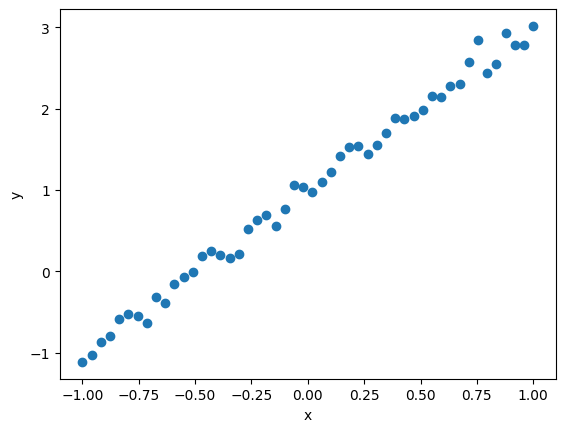

In [4]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0) #imposta il seme 0 almeno genera sempre gli stessi numeri casuali

X = torch.linspace(-1, 1, 50) # genera 50 numeri equidistanti tra -1 e 1
print(X[:5])
print(X.shape)
Y = 2*X + 1 + 0.1*torch.randn(50) # 0.1*torch.randn(50) crea rumore

plt.scatter(X, Y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
#prediction
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

pred = w*X + b
print(pred[:5])

tensor([-1.0000, -0.9184, -0.8367, -0.7551, -0.6735], grad_fn=<SliceBackward0>)


In [ ]:
#calcolo del loss
loss = ((pred - Y)**2).mean()
print(loss)

tensor(0.0116, grad_fn=<MeanBackward0>)


In [ ]:
#gradiente
loss.backward()
print(w.grad)
print(b.grad)

tensor(-0.0199)
tensor(-0.0098)


In [ ]:
#prova con entrambi i casi - più è accurato più la loss e il gradiente sono bassi
for w_val, b_val in [(0.0, 0.0), (2.0, 1.0)]:
    w = torch.tensor(w_val, requires_grad=True)
    b = torch.tensor(b_val, requires_grad=True)
    loss = ((w*X + b - Y)**2).mean()
    loss.backward()
    print(f"w={w_val}, b={b_val} -> loss={loss.item():.4f}, "
          f"w.grad={w.grad.item():.3f}, b.grad={b.grad.item():.3f}")

w=0.0, b=0.0 -> loss=2.4489, w.grad=-1.408, b.grad=-2.010
w=2.0, b=1.0 -> loss=0.0116, w.grad=-0.020, b.grad=-0.010


In [ ]:
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
lr = 0.5

# 1. quanto sbaglia ora
loss = ((w*X + b - Y)**2).mean()
print("loss prima:", loss.item())

# 2. in che direzione è la discesa
loss.backward()
print("w.grad:", w.grad.item(), " b.grad:", b.grad.item())

# 3. un passo nella direzione opposta al gradiente
with torch.no_grad():
    w_new = w - lr * w.grad
    b_new = b - lr * b.grad
print("w nuovo:", w_new.item(), " b nuovo:", b_new.item())

# 4. quanto sbaglia dopo il passo
loss_dopo = ((w_new*X + b_new - Y)**2).mean()
print("loss dopo:", loss_dopo.item())

loss prima: 2.4489264488220215
w.grad: -1.4076541662216187  b.grad: -2.0097639560699463
w nuovo: 7.038270950317383  b nuovo: 10.048819541931152
loss dopo: 90.5108871459961


In [ ]:
#ora tutto assieme
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
lr = 0.1
losses = []

for step in range(100):
    loss = ((w*X + b - Y)**2).mean()    # 1. quanto sbaglia
    loss.backward()                     # 2. calcola i gradienti

    losses.append(loss.item())
    if step % 10 == 0:
        print(step, round(loss.item(), 4), round(w.item(), 3), round(b.item(), 3))

    with torch.no_grad():               # 3. passo in discesa
        w -= lr * w.grad
        b -= lr * b.grad

    w.grad.zero_()                      # 4. azzera i gradienti
    b.grad.zero_()

0 2.4489 0.0 0.0
10 0.3618 1.04 0.897
20 0.0919 1.547 0.993
30 0.0304 1.794 1.004
40 0.0158 1.914 1.005
50 0.0124 1.973 1.005
60 0.0116 2.002 1.005
70 0.0114 2.015 1.005
80 0.0113 2.022 1.005
90 0.0113 2.026 1.005


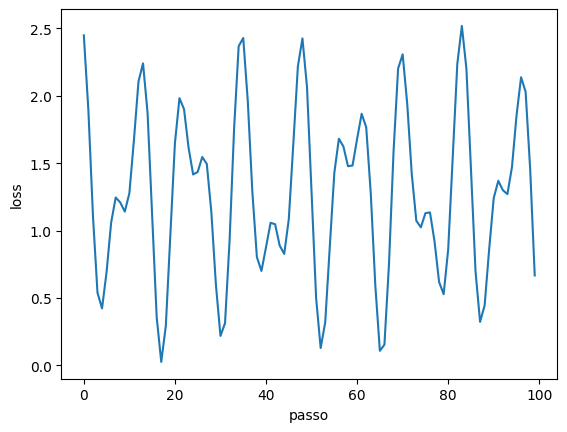

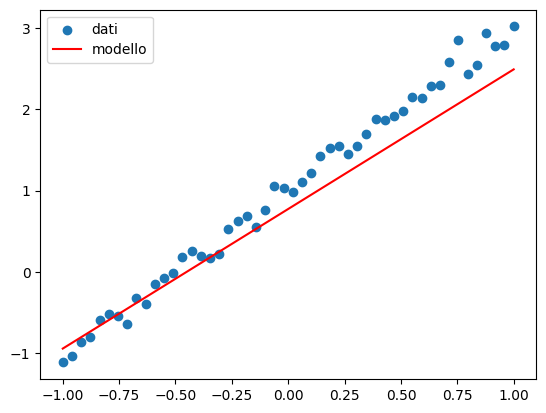

In [ ]:
plt.plot(losses)
plt.xlabel("passo")
plt.ylabel("loss")
plt.show()

plt.scatter(X, Y, label="dati")
plt.plot(X, (w*X + b).detach(), color="red", label="modello")
plt.legend()
plt.show()

Parte 3

In [1]:
import torch.nn as nn

model = nn.Linear(1, 1)
print(model)
print(model.weight)
print(model.bias)

Linear(in_features=1, out_features=1, bias=True)
Parameter containing:
tensor([[0.9922]], requires_grad=True)
Parameter containing:
tensor([0.7526], requires_grad=True)


In [5]:
with torch.no_grad():
    model.weight.fill_(0.0)
    model.bias.fill_(0.0)

print(model.weight.item(), model.bias.item())

0.0 0.0


In [10]:
Xc = X.unsqueeze(1)
Yc = Y.unsqueeze(1)
print(X.shape, "->", Xc.shape)

pred = model(Xc)
print(pred.shape)
print(pred[:3])

torch.Size([50]) -> torch.Size([50, 1])
torch.Size([50, 1])
tensor([[0.],
        [0.],
        [0.]], grad_fn=<SliceBackward0>)


In [11]:
loss = ((pred - Yc)**2).mean()
print("loss:", loss.item())

loss.backward()
print("weight.grad:", model.weight.grad.item())
print("bias.grad:", model.bias.grad.item())

loss: 2.4489264488220215
weight.grad: -2.8153085708618164
bias.grad: -4.019527912139893


Sostituzioni con funzioni già presenti

In [13]:
model = nn.Linear(1, 1)
with torch.no_grad():
    model.weight.fill_(0.0)
    model.bias.fill_(0.0)

In [14]:
loss_fn = nn.MSELoss() # Mean Squared Error

pred = model(Xc)
loss = loss_fn(pred, Yc)
print(loss.item())

2.4489264488220215


In [16]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent modifica lui il gradiente

In [19]:
optimizer.zero_grad()           # azzera i gradienti
pred = model(Xc)                # previsione
loss = loss_fn(pred, Yc)        # quanto sbaglia
loss.backward()                 # calcola i gradienti
optimizer.step()                # aggiorna i parametri

print("w:", model.weight.item(), " b:", model.bias.item())
print("loss prima:", loss.item())

w: 0.2717634439468384  b: 0.3617575168609619
loss prima: 1.8941280841827393


In [20]:
loss_dopo = loss_fn(model(Xc), Yc)
print("loss dopo:", loss_dopo.item())

loss dopo: 1.4958219528198242


ora tutto assieme

In [21]:
model = nn.Linear(1, 1)
with torch.no_grad():
    model.weight.fill_(0.0)
    model.bias.fill_(0.0)

loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
losses = []

for step in range(100):
    optimizer.zero_grad()
    pred = model(Xc)
    loss = loss_fn(pred, Yc)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if step % 10 == 0:
        print(step, round(loss.item(), 4),
              round(model.weight.item(), 3), round(model.bias.item(), 3))

0 2.4489 0.141 0.201
10 0.3618 1.109 0.919
20 0.0919 1.581 0.996
30 0.0304 1.81 1.004
40 0.0158 1.922 1.005
50 0.0124 1.977 1.005
60 0.0116 2.003 1.005
70 0.0114 2.016 1.005
80 0.0113 2.023 1.005
90 0.0113 2.026 1.005


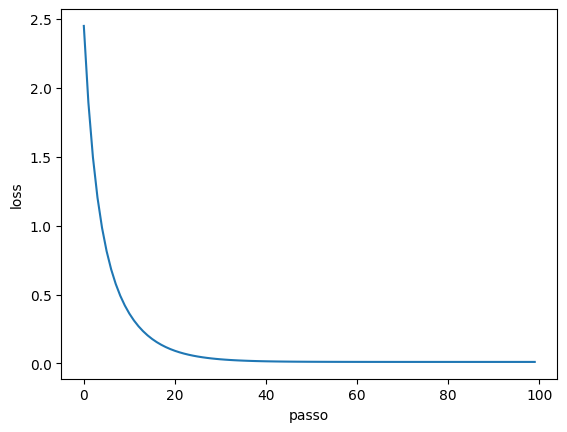

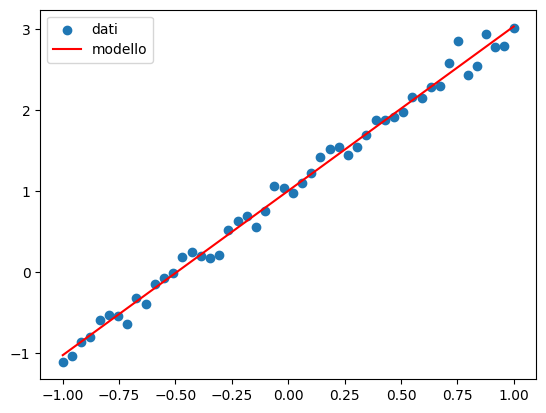

In [22]:
plt.plot(losses)
plt.xlabel("passo")
plt.ylabel("loss")
plt.show()

plt.scatter(X, Y, label="dati")
plt.plot(X, model(Xc).detach(), color="red", label="modello")
plt.legend()
plt.show()